In [ ]:
This notebook uses synthetic data generated in Python, to demonstrate the analysis workflow

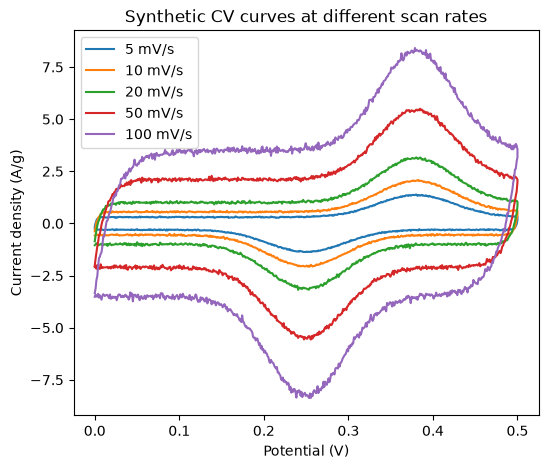

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Settings for our fake electrode
mass = 0.002                              # active mass in grams (2 mg)
scan_rates = [5, 10, 20, 50, 100]         # mV/s
Cs_cap = {5: 60, 10: 55, 20: 50, 50: 42, 100: 35}   # capacitive part, F/g (drops at high rates)
V_min, V_max = 0.0, 0.5                   # potential window in volts
R = 3.0                                   # series resistance in ohms
E_ox, E_red, width = 0.38, 0.25, 0.045    # redox peak positions and width (V)
A = 15                                    # peak size factor

rng = np.random.default_rng(42)           # makes the random noise repeatable

def make_cv(scan_rate, Cs, n=500, cycles=2):
    """Make one fake CV curve: returns potential (V) and current density (A/g)."""
    v = scan_rate / 1000                  # mV/s -> V/s
    C = Cs * mass                         # total capacitance in farads
    tau = R * C
    sweep = np.concatenate([np.linspace(V_min, V_max, n),
                            np.linspace(V_max, V_min, n)])
    E = np.tile(sweep, cycles)
    dt = (V_max - V_min) / v / n

    # 1) capacitive current (box shape with rounded corners)
    Vc = V_min
    I_cap = np.zeros_like(E)
    for k in range(len(E)):
        Vc_old = Vc
        Vc += (E[k] - Vc) * (1 - np.exp(-dt / tau))
        I_cap[k] = C * (Vc - Vc_old) / dt

    # 2) redox peaks (anodic on the way up, cathodic on the way down)
    going_up = np.tile(np.r_[np.ones(n), np.zeros(n)], cycles).astype(bool)
    peak_size = A * np.sqrt(v) * mass     # peak current grows with sqrt(scan rate)
    I_far = np.where(going_up,
                     peak_size * np.exp(-0.5 * ((E - E_ox) / width) ** 2),
                     -peak_size * np.exp(-0.5 * ((E - E_red) / width) ** 2))

    I = I_cap + I_far
    I += rng.normal(0, 0.01 * np.max(np.abs(I)), size=I.size)   # about 1% noise
    return E[-2*n:], I[-2*n:] / mass      # last cycle, current density in A/g

# Make and plot all curves
cv_data = {}
plt.figure(figsize=(6, 5))
for sr in scan_rates:
    E, J = make_cv(sr, Cs_cap[sr])
    cv_data[sr] = (E, J)
    plt.plot(E, J, label=f"{sr} mV/s")

plt.xlabel("Potential (V)")
plt.ylabel("Current density (A/g)")
plt.title("Synthetic CV curves at different scan rates")
plt.legend()
plt.show()

   5 mV/s  ->   107.8 F/g
  10 mV/s  ->    88.3 F/g
  20 mV/s  ->    72.8 F/g
  50 mV/s  ->    55.2 F/g
 100 mV/s  ->    42.8 F/g


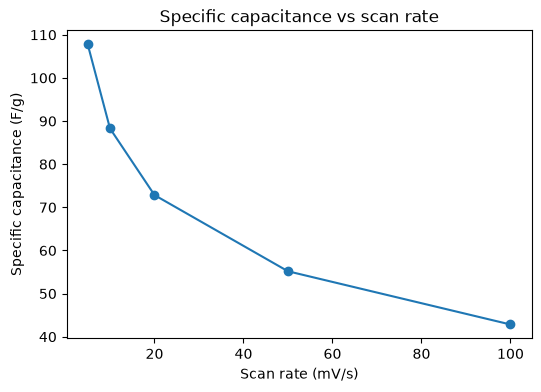

In [4]:
def loop_area(E, J):
    """Area inside the CV loop (A/g x V), using the trapezoid rule."""
    return np.sum(0.5 * (J[1:] + J[:-1]) * np.diff(E))

delta_V = V_max - V_min      # potential window in volts
results = []

for sr in scan_rates:
    E, J = cv_data[sr]
    v = sr / 1000                                   # mV/s -> V/s
    C_spec = loop_area(E, J) / (2 * v * delta_V)    # specific capacitance in F/g
    results.append(C_spec)
    print(f"{sr:>4} mV/s  ->  {C_spec:6.1f} F/g")

plt.figure(figsize=(6, 4))
plt.plot(scan_rates, results, "o-")
plt.xlabel("Scan rate (mV/s)")
plt.ylabel("Specific capacitance (F/g)")
plt.title("Specific capacitance vs scan rate")
plt.show()

In [ ]:
Specific capacitance decreases with increasing scan rate because ion diffusion cannot keep up with fast potential sweeps, so less of the active surface is used.